# **Build your First RAG Agent**


> **What you'll build:** a tutor that answers from *your own PDF notes*. This notebook explains each RAG step before the code. Repo: see `README.md` and `docs/how-rag-works.md`.

**Run it in Colab:** add your key under 🔑 Secrets as `GEMINI_API_KEY`.

In [ ]:
!pip -q install pymupdf sentence-transformers google-genai gradio

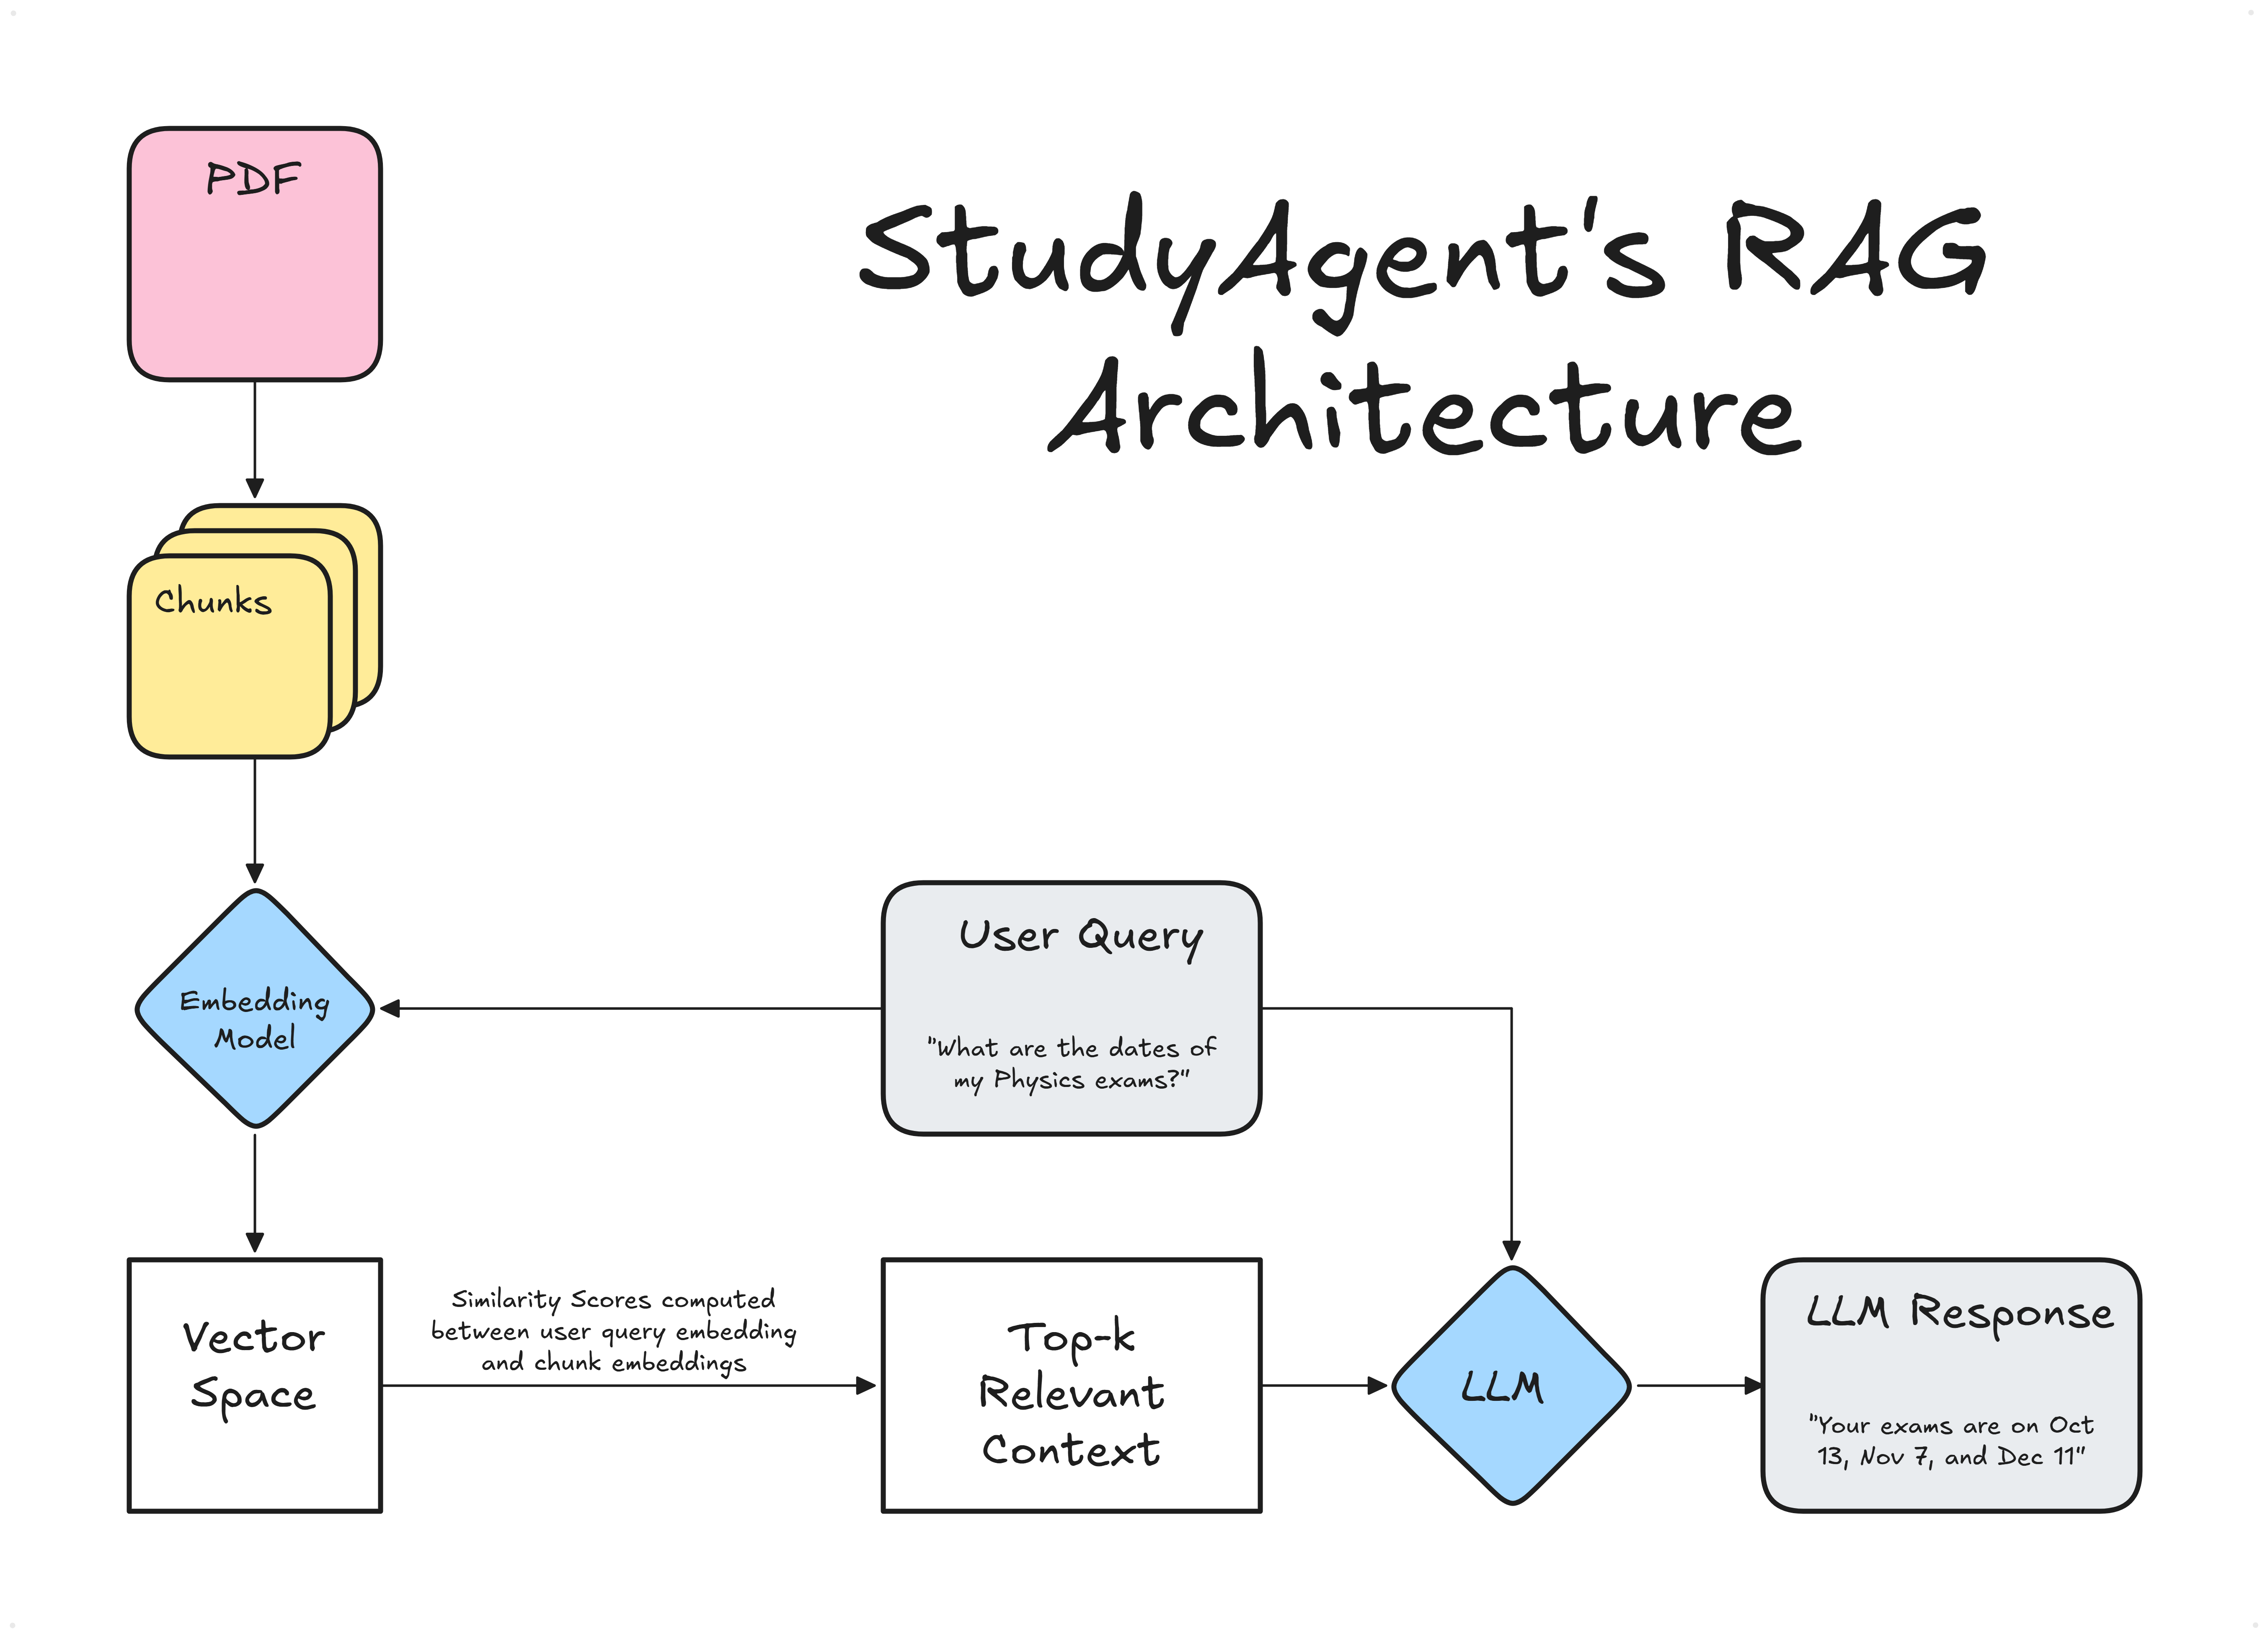

## **Retrieval-Augmented Generation**

### Step 1: Load the document
Extract the raw text from a PDF. If this returns 0 characters, the PDF is probably scanned images and needs OCR.

### Loading Docs

In [ ]:
import pymupdf
from google.colab import files

In [ ]:
# TODO: File uploads
uploaded= files.upload()
pdf_path=next(iter(uploaded))

doc= pymupdf.open(pdf_path)

text=''
for page in doc:
    text+=page.get_text()

In [ ]:
print(f"Extracted {len(doc)} pages and {len(text)} characters")

### Steps 2-3: Chunk and embed
**Chunking** splits text into 1000-character pieces (200 overlap) so we can search precisely. **Embedding** turns each chunk into a vector where *similar meaning = similar direction*.

### Chunking & Embedding

In [ ]:
def chunk_text(text, chunk_size=1000, overlap=200):
    chunks = []
    for i in range(0, len(text), chunk_size - overlap):
        chunks.append(text[i:i + chunk_size])

    return chunks

In [ ]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    'sentence-transformers/all-MiniLM-L6-v2'
)

In [ ]:
def embed_chunks(model, chunks):
    embeddings = model.encode(chunks,
                              normalize_embeddings=True)
    return embeddings

### Step 4: Search by meaning
Embed the question, compare it with every chunk (dot product = cosine similarity because vectors are normalised), keep the top-k.

### Finding Highest-Relevance Docs

In [ ]:
def similarities(query, model, embeddings, topk):
    query_embeddings = model.encode(
        query, normalize_embeddings=True
    )

    #Calculate the scores
    scores= query_embeddings @ embeddings.T


    #Retrieve the top-k highest scores

    top_indices= scores.argsort()[-topk:][::-1]


    return top_indices

### Step 5: Retrieval, tested on its own
Before adding any LLM, check retrieval works. If the right passages don't come back here, no prompt can fix it.

### RAG

In [ ]:
def rag(query, embedding_model, chunks, embeddings, topk=5):
    top_indices = similarities(query, embedding_model, embeddings, topk)

    relevant_chunks=[chunks[i] for i in top_indices]

    return relevant_chunks

In [ ]:
query = "What is one important concept in these notes?"

chunks = chunk_text(text)
embeddings = embed_chunks(embedding_model, chunks)
for i, chunk in enumerate(
    rag(query, embedding_model, chunks, embeddings),
    start=1
):
    print(f"\n--- Result {i} ---")
    print(chunk[:500])

## Step 6: Turn it into an agent
Instead of retrieving once, we give the LLM a **tool** (`search_notes`) and let it decide when to search. That's agentic RAG.

## **Turning this into an Agent**

In [ ]:
from google import genai
from google.genai import types
from google.colab import userdata
import os

### Our LLM

In [ ]:
GEMINI_API_KEY = userdata.get('GEMINI_API_KEY')

client = genai.Client(
    api_key=GEMINI_API_KEY
)

MODEL = 'gemini-3.5-flash-lite'

In [ ]:
response = client.models.generate_content(
    model=MODEL,
    contents="What is Retrieval-Augmented Generation?"
)
print(response.text)

### Search Notes Tool

In [ ]:
def search_notes(query: str) -> str: #This is basically the RAG function we created
    relevant_chunks= rag(query, embedding_model, chunks, embeddings)

    return "\n".join(relevant_chunks)

### The system prompt
This defines the tutor's behaviour: stay grounded in the notes, quiz one question at a time, and use conversation history.

### Building the Context

In [ ]:
SYSTEM_PROMPT = """
You are StudyAgent, an AI tutor that helps students learn from their uploaded class notes.

Your goal is to help the student understand and study the material in their notes.

You can:
- Answer questions about the course material
- Explain difficult concepts in simple terms
- Quiz the student on their notes
- Give hints when the student is stuck
- Evaluate the student's answers and explain mistakes
- Help the student review for exams

You have access to a tool called search_notes that searches the student's uploaded notes.

Use search_notes whenever you need information from the student's course material.
Base course-specific answers on the information returned by search_notes rather than
making up information.

CONVERSATION:
- Pay attention to the full conversation history.
- Interpret short responses like "yes", "no", "sure", "anything", "go ahead",
  and "continue" in the context of the previous messages.
- Do not ask the student to repeat information or make a choice they have already made.
- If you offer to start a quiz and the student agrees, immediately begin the quiz.
- If the student says "anything" after agreeing to a quiz, choose a topic yourself
  from the notes and begin.
- Continue the current activity unless the student clearly asks to change it.

WHEN QUIZZING:
- Use search_notes to find material to quiz the student on.
- Ask one question at a time.
- Do not reveal the answer before the student responds.
- Wait for the student's answer.
- Evaluate their response and explain what they got right or wrong.
- Then ask the next question.
- If the student does not specify a topic, choose one from their notes yourself.

Be encouraging, clear, and concise.
Adapt your explanations to the student's apparent level of understanding.
"""

In [ ]:
def study_agent(query, history=None) -> list[str]:
    history = history or []
    contents = []

    for message in history:
        role = message['role'] if isinstance(message, dict) else message.role
        content = message['content'] if isinstance(message, dict) else message.content

        if role not in {'user', 'assistant'}:
            continue

        if not isinstance(content, str):
            continue

        gemini_role = 'model' if role == 'assistant' else 'user'

        contents.append(
            types.Content(
                role=gemini_role,
                parts=[types.Part.from_text(text=content)]
            )
        )

    contents.append(
        types.Content(
            role='user',
            parts=[types.Part.from_text(text=query)]
        )
    )

    response = client.models.generate_content(
        model=MODEL,
        contents=contents,
        config=types.GenerateContentConfig(
            system_instruction=SYSTEM_PROMPT,
            tools=[search_notes]
        )
    )

    return response.text


In [ ]:
print(study_agent("According to my notes, give me a summary."))

## Step 7: Put it all together
A Gradio UI for upload + chat. (In the repo this is refactored into `src/studyagent/` with per-session state.)

## **Putting it all together**

In [ ]:
import gradio as gr

chunks = []
embeddings = None

In [ ]:
def process_pdf(file_path):
    global chunks, embeddings

    with pymupdf.open(file_path) as doc:
        text = ""

        for page in doc:
            text += page.get_text()

        num_pages = len(doc)

    if not text.strip():
        chunks = []
        embeddings = None
        return "I couldn't extract text from that PDF."

    chunks = chunk_text(text)

    embeddings = embed_chunks(
        embedding_model,
        chunks
    )

    return (
        f"  **Notes are ready!**  \n"
        f"**Pages:** {num_pages}  \n"
        f"**Chunks:** {len(chunks)}"
    )

In [ ]:
def respond(message, history):
    history = history or []

    if not message or not message.strip():
        return "", history

    if embeddings is None or len(chunks) == 0:
        response = "Please upload and process your PDF before starting a study session."
    else:
        try:
            response = study_agent(message, history)
        except Exception as e:
            response = f"Something went wrong: {e}"

    history = history + [
        {"role": "user", "content": message},
        {"role": "assistant", "content": response}
    ]

    return "", history

In [ ]:
CSS = """
#title {
    text-align: center;
    margin-bottom: 0;
}

#subtitle {
    text-align: center;
    opacity: 0.72;
    margin-bottom: 18px;
}

#sidebar {
    padding: 8px;
}
"""

with gr.Blocks() as demo:

    gr.Markdown(
        "# 📚 StudyAgent",
        elem_id="title"
    )

    gr.Markdown(
        "Upload your class notes and study with your own AI tutor.",
        elem_id="subtitle"
    )

    with gr.Row():

        with gr.Column(scale=1, min_width=300, elem_id="sidebar"):

            gr.Markdown("### Course Material")

            pdf_upload = gr.File(
                label="Upload your notes",
                file_types=[".pdf"],
                type="filepath"
            )

            process_button = gr.Button(
                "Process Notes",
                variant="primary"
            )

            status = gr.Markdown(
                "Upload a PDF to get started."
            )

            gr.Markdown(
                "**Try:** lecture slides, class notes, textbook chapters, or a study guide."
            )

        with gr.Column(scale=2):

            gr.Markdown("### Study Session")

            chatbot = gr.Chatbot(
                height=500,
                placeholder=(
                    "<strong>StudyAgent</strong><br>"
                    "Process your notes, then ask me anything or say <em>Quiz me!</em>"
                )
            )

            message = gr.Textbox(
                placeholder='Ask a question or say "Quiz me!"',
                label="Message",
                lines=2
            )

            with gr.Row():
                send_button = gr.Button(
                    "Send",
                    variant="primary"
                )

                clear_button = gr.Button(
                    "Clear Chat"
                )

    process_button.click(
        fn=process_pdf,
        inputs=pdf_upload,
        outputs=status
    )

    send_button.click(
        fn=respond,
        inputs=[message, chatbot],
        outputs=[message, chatbot]
    )

    message.submit(
        fn=respond,
        inputs=[message, chatbot],
        outputs=[message, chatbot]
    )

    clear_button.click(
        fn=lambda: ("", []),
        outputs=[message, chatbot]
    )

In [ ]:
demo.launch(
    debug=True,
    theme=gr.themes.Soft(),
    css=CSS
)